In [3]:
import numpy as np
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
import torch
import sys 
import tifffile 
from pathlib import Path
from scripts.utils import reshape_disp, reshape_img, rmse
import torchio as tio
import ast
import napari
import re
from bioio import BioImage

from scripts.dataset import compute_mask
sys.path.append('/Users/josephinelahmani/Desktop/vxmorph') 
from typing import Tuple
import importlib
import network
import network.models
import scripts.dataset
importlib.reload(network.models)
importlib.reload(network)
importlib.reload(scripts.dataset)
from scripts.dataset import TractionDataset
from torch.utils.data import DataLoader
from scripts.train import epoch_, update_log
from tqdm import tqdm
import importlib
import network.losses
importlib.reload(network.losses)
import network.functional
importlib.reload(network.functional)
import scripts.train
importlib.reload(scripts.train)
import yaml
import optical_flow.algorithms
importlib.reload(optical_flow.algorithms)
from optical_flow.algorithms import tv_l1, fista_of, hs_of
from scripts.register import register

import scipy.ndimage as ndi

from quantities_computation import strain_mask, deformation, stress_mask, compute_normals_from_mask_3d, compute_traction_3d
import json
import csv

/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data observation

In [2]:
# img = np.load(Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy'))
# viewer = napari.Viewer()

# viewer.add_image(img, name='Original', scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

## Augmentations

In [5]:
def get_transformed_img(img_path: Path, transform, channel=0):
        device = 'cpu'
        
        img_raw = tifffile.imread(img_path)        
        data = (
            img_raw[:, channel] if channel is not None else img_raw
        )  # Normalize the channel if provided
        q1, q99 = np.quantile(data, [0.01, 0.99])
        img = np.clip((data - q1) / (q99 - q1), 0, 1)

        source_numpy = img[1]
        target_numpy = img[0]

        source = reshape_img(source_numpy, 32)  # (Z, H, W)
        target = reshape_img(target_numpy, 32)  # (Z, H, W)
        
        source = torch.from_numpy(source).to(device)
        target = torch.from_numpy(target).to(device)
        
        scalar_img = torch.stack([source, target], dim=0) # (2, Z, H, W)
        
        subject = tio.Subject(stack = tio.ScalarImage(tensor=scalar_img))
        
        subject = transform(subject)
        
        transformed = subject.stack.data.numpy()
        
        return np.stack([source, target], axis=0)[:,0], transformed

In [9]:
path_img_micro = Path('/Users/josephinelahmani/helix_mount/data/micro/test/250218_WT_1p5CD100RGD_pos1_t0021_t0024.tiff') 
path_img_synt = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_01_seed_05_img.npy') 

transforms = {
    "RandomFlip": tio.RandomFlip(axes=("LR",), flip_probability=1.0),
    "RandomAffine":tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=10),
    "RandomNoise": tio.RandomNoise(std=(0, 0.1)),
    "RandomGamma": tio.RandomGamma(log_gamma=(-0.8, 0.8)),
    "RandomBlur": tio.RandomBlur(std=(0, 1)), 
    "ComposeAll": tio.Compose(
        [
            tio.RandomFlip(axes=("LR",), flip_probability=1.0),
            tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=8),
            tio.RandomNoise(std=(0, 0.1)),
            tio.RandomBlur(std=(0, 1)), 
        ]
    )
}

In [11]:
# viewer = napari.Viewer()

# for key, value in transforms.items(): 
#     img, transformed = get_transformed_img(path_img_micro, value)
#     viewer.add_image(transformed, name=key, scale=(1.0, 0.13, 0.13), interpolation3d='nearest')
    
# viewer.add_image(img, name='Original', scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

In [6]:
# viewer_all = napari.Viewer()

# img, transformed = get_transformed_img(path_img_synt, transforms["ComposeAll"])
# viewer_all.add_image(transformed, scale=(1.0, 0.13, 0.13), interpolation3d='nearest')

## Masks

In [7]:
# mask = compute_mask(img)

# mask.shape

# plt.imshow(mask)

# Model

In [4]:
def plot_loss(folder:str, loss_part:str, init_epoch:int=0):
    if loss_part == 'total':
        name = 'loss'
    else:
        name = f'loss_{loss_part}'

    train_logs = pd.read_csv(f'{folder}/logs_train.csv').iloc[init_epoch:]
    val_logs  = pd.read_csv(f'{folder}/logs_validation.csv').iloc[init_epoch:]

    epochs = range(init_epoch + 1, len(train_logs) + init_epoch + 1)
    
    plt.plot(epochs, train_logs[name], label='train loss', color='blue')
    plt.plot(epochs, val_logs[name], label='val loss', color='red')
    plt.title(f'{name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()


def check_vxm(img_padded: np.ndarray, warped_image:np.ndarray, z_stack: int):
        
        diff_init = np.abs(img_padded[1, z_stack] - img_padded[0, z_stack])
        diff_warped = np.abs(warped_image[z_stack] - img_padded[0, z_stack])
        
        print('Average difference original image', np.mean(diff_init))
        print('Average difference warped image', np.mean(diff_warped))
        
        vmin_im, vmax_im = np.min(img_padded[0, z_stack]), np.max(img_padded[0, z_stack])
        
        vmin = np.min([np.min(diff_init), np.min(diff_warped)])
        vmax = np.max([np.max(diff_init), np.max(diff_warped)])
        
        fig, axes = plt.subplots(1, 5, figsize=(24, 6))
        
        im0 = axes[0].imshow(img_padded[0, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[0].set_title('I1')
        fig.colorbar(im0, ax=axes[0])
        im1 = axes[1].imshow(img_padded[1, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[1].set_title('I2')
        fig.colorbar(im1, ax=axes[1])
        im2 = axes[2].imshow(warped_image[z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[2].set_title("I2(x+u)")
        fig.colorbar(im2, ax=axes[2])
        im3 = axes[3].imshow(diff_init, vmin=vmin, vmax=vmax)
        axes[3].set_title("I2 - I1 (absolute value)")
        fig.colorbar(im3, ax=axes[3])
        im4 = axes[4].imshow(diff_warped, vmin=vmin, vmax=vmax)
        axes[4].set_title("I2(x+u) - I1 (absolute value)")
        fig.colorbar(im4, ax=axes[4])
        plt.show()

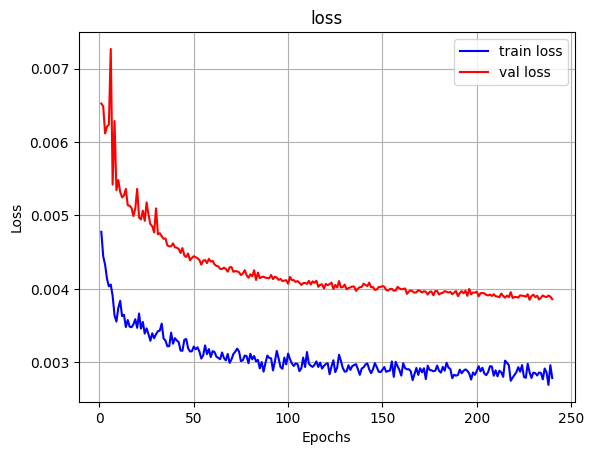

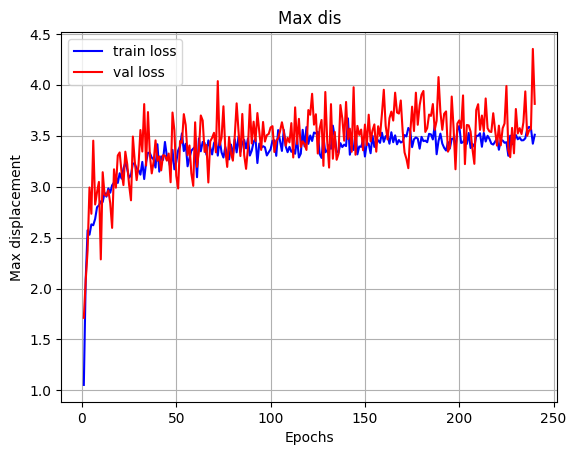

In [32]:
results_folder = '/Users/josephinelahmani/helix_mount/nn_dis/results/train_9' #'/Users/josephinelahmani/helix_mount/nn_dis/results/train_3_mask_new_data'

### Plot loss

plot_loss(results_folder, 'total', 0)

### Plot max dis

train_logs = pd.read_csv(f'{results_folder}/logs_train.csv')
val_logs  = pd.read_csv(f'{results_folder}/logs_validation.csv')
    
epochs = range(1, len(train_logs) + 1)

plt.plot(epochs, train_logs["max_dis"], label='train loss', color='blue')
plt.plot(epochs, val_logs["max_dis"], label='val loss', color='red')
plt.title('Max dis')
plt.xlabel('Epochs')
plt.ylabel('Max displacement')
plt.legend()
plt.grid(True)
plt.show()

Attempted file (/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif'. Failed to parse XML for the provided file. Error: not well-formed (invalid token): line 1, column 6


Average difference original image 0.020203672
Average difference warped image 0.0062452387


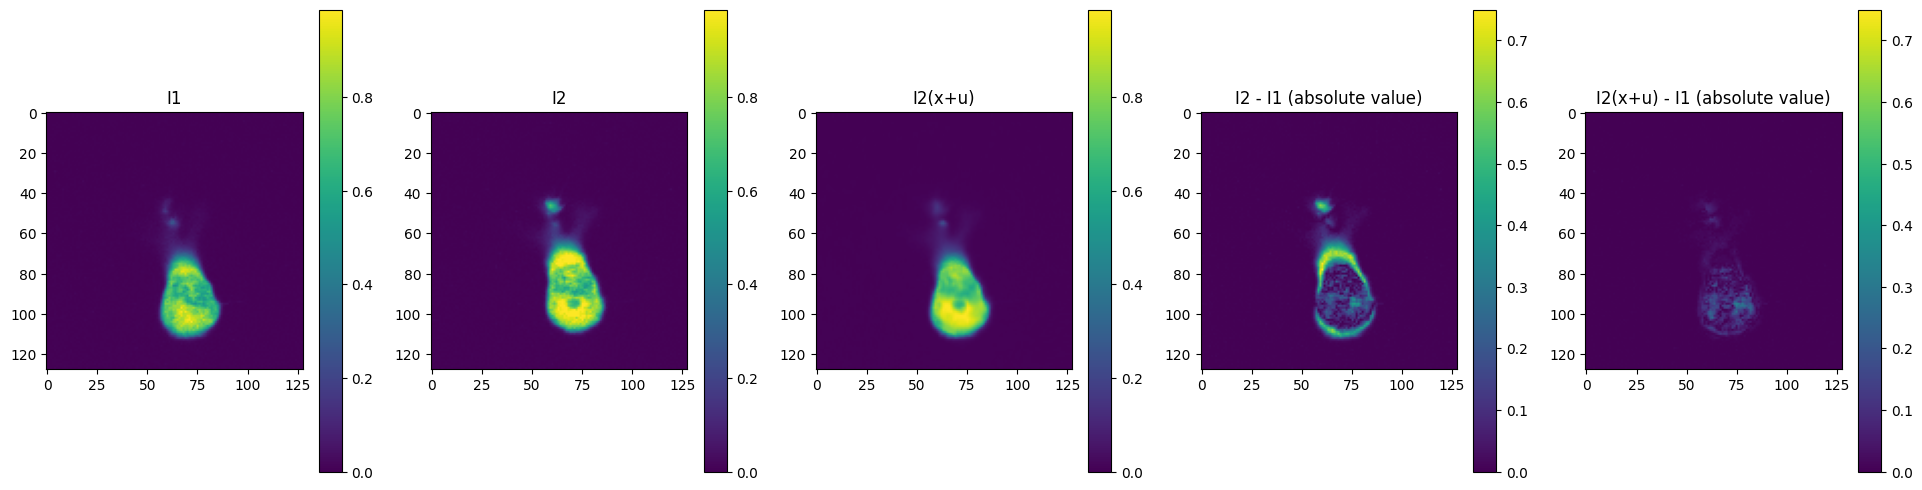

In [33]:
crop = [(10,42), (300,750), (150,500)] # None
path_img = Path('/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif') #Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy') 
channel = 2 # None
default_spacing = None #[1.0, 0.13, 0.13]

img, spacing, dis, ws = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5, channel=channel, default_spacing=default_spacing, crop=crop)

z_stack = 20

check_vxm(img, ws, z_stack=z_stack)

In [16]:
diff_im = img[1] - img[0]
diff_w = ws - img[0]

def rmse_(diff):
    return np.sqrt(np.mean(diff**2))

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im))
print('warped - I1:', np.linalg.norm(diff_w))

print('RMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped - I1:', rmse_(diff_w))

Norms
I2 - I1: 38.618954
warped - I1: 9.953716
RMSE
I2 - I1: 0.053335447
warped - I1: 0.0137467645


In [5]:
# viewer = napari.Viewer()
# viewer.add_image(img_padded, scale=new_spacing)

Min: -0.5644
Max: 0.7745
Mean abs: 0.1098


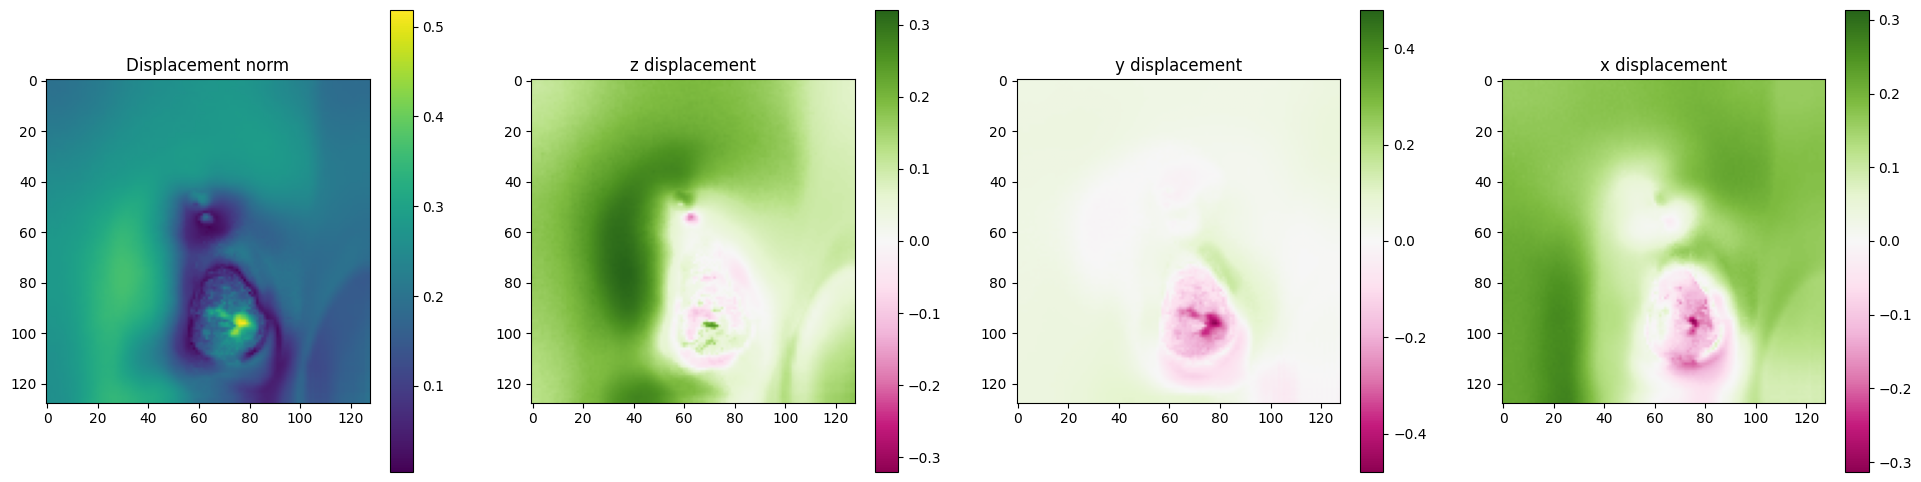

In [20]:
### Visualize displacement results

dis = dis.detach().numpy()

print(f"Min: {dis.min():.4f}")
print(f"Max: {dis.max():.4f}")
print(f"Mean abs: {np.abs(dis).mean():.4f}")

dis_z_max = np.max(np.abs(dis[0, 0, z_stack]))
dis_y_max = np.max(np.abs(dis[0, 1, z_stack]))
dis_x_max = np.max(np.abs(dis[0, 2, z_stack]))

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

im0 = axes[0].imshow(np.linalg.norm(dis[0, :, z_stack], axis=0))
fig.colorbar(im0, ax = axes[0])
axes[0].set_title('Displacement norm')
im1 = axes[1].imshow(dis[0, 0, z_stack], cmap = 'PiYG', vmin = -dis_z_max, vmax = dis_z_max)
fig.colorbar(im1, ax = axes[1])
axes[1].set_title('z displacement')
im2 = axes[2].imshow(dis[0, 1, z_stack], cmap = 'PiYG', vmin = -dis_y_max, vmax = dis_y_max)
fig.colorbar(im2, ax = axes[2])
axes[2].set_title('y displacement')
im3 = axes[3].imshow(dis[0, 2, z_stack], cmap = 'PiYG', vmin = -dis_x_max, vmax = dis_x_max)
fig.colorbar(im3, ax = axes[3])
axes[3].set_title('x displacement')
plt.show()

# Model comparisons

In [18]:
def rmse_(diff):
    return float(np.sqrt(np.mean(diff ** 2)))

def save_flow_vxm(folder_img: Path, results_folder: Path, name:str, save_path:Path = None, channel:int = None, crop: Tuple[Tuple[int, int], Tuple[int, int], Tuple[int, int]] = None, default_spacing: Tuple[float]=None):
    save_path.mkdir(exist_ok=True)
    
    metrics_rows = []

    for path_img in folder_img.iterdir():
        ext = os.path.splitext(path_img)[1].lower()
        if ext in [".npy", ".tiff", ".tif"]:
            img_padded, spacing, dis, warped_im = register(img_path=path_img, folder_path=results_folder, channel=channel, crop=crop, default_spacing=default_spacing)

            mask_padded = img_padded[0] > 0.1
            dis_vxm = dis.detach().numpy()
            dis_vxm_final = np.stack([dis_vxm[:,i] * mask_padded for i in range(dis_vxm.shape[1])])
            
            diff_im = img_padded[1] - img_padded[0]
            diff_warped = warped_im - img_padded[0]

            norm_I2_I1 = np.linalg.norm(diff_im)
            norm_warped_I1 = np.linalg.norm(diff_warped)

            rmse_I2_I1 = rmse_(diff_im)
            rmse_warped_I1 = rmse_(diff_warped)
            
            metrics_rows.append({
                        "model": name,
                        "image": path_img.name,
                        "norm_I2_minus_I1": float(norm_I2_I1),
                        "rmse_I2_minus_I1": float(rmse_I2_I1),
                        "norm_warped_minus_I1": float(norm_warped_I1),
                        "rmse_warped_minus_I1": float(rmse_warped_I1),
                    })

            if save_path is not None :
                np.save(save_path / f"flow_vxm_{path_img.name}_{name}", dis_vxm_final)
                np.save(save_path / f"warped_im_vxm_{path_img.name}_{name}", warped_im)
                np.save(save_path / f"init_im_{path_img.name}_{name}", img_padded)
            
        mean_row = {
            "model": name,
            "image": "MEAN",
            "norm_I2_minus_I1": float(np.mean([
                row["norm_I2_minus_I1"] for row in metrics_rows
            ])),
            "rmse_I2_minus_I1": float(np.mean([
                row["rmse_I2_minus_I1"] for row in metrics_rows
            ])),
            "norm_warped_minus_I1": float(np.mean([
                row["norm_warped_minus_I1"] for row in metrics_rows
            ])),
            "rmse_warped_I1": float(np.mean([
                row["rmse_warped_minus_I1"] for row in metrics_rows
            ])),
        }
    
    mean_row["rmse_warped_minus_I1"] = mean_row.pop("rmse_warped_I1")
    metrics_rows.append(mean_row)

    csv_path = results_folder / f"metrics_vxm_{name}.csv"

    fieldnames = [
        "model",
        "image",
        "norm_I2_minus_I1",
        "rmse_I2_minus_I1",
        "norm_warped_minus_I1",
        "rmse_warped_minus_I1",
    ]

    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(metrics_rows)
        
    return metrics_rows
            

models_to_compare = {
    'train_1': 'a_0.2_b_0.01',
    'train_2': 'a_0.3_b_0.1',
    'train_3': 'a_0.25_b_0.05',
    'train_5': 'a_b_0.2', 
    'train_6_': 'a_b_0.1',
    'train_7': 'a_0.2_b_0', 
    'train_8': 'a_0.1_b_0', 
    'train_9': 'a_0.1_b_0 both types'
}

channel = None
crop = None
default_spacing = [1.0, 0.13, 0.13]
base_img_folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
base_results_folder = Path('/Users/josephinelahmani/helix_mount/nn_dis/results')
save_path = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm')

for model_folder, name in models_to_compare.items():
    results_folder = base_results_folder / model_folder
    save_flow_vxm(base_img_folder, results_folder, name, save_path, channel, crop, default_spacing)

In [19]:
for model_folder, name in models_to_compare.items():
    csv_path = f'{base_results_folder}/{model_folder}/metrics_vxm_{name}.csv'
    with open(csv_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if row["image"] == "MEAN":
                norm_warped = float(row["norm_warped_minus_I1"])
                rmse_warped = float(row["rmse_warped_minus_I1"])

                print(
                    f"{name:20s} | "
                    f"Norm warped - I1: {norm_warped:.6f} | "
                    f"RMSE warped - I1: {rmse_warped:.6f}"
                )
                break


a_0.2_b_0.01         | Norm warped - I1: 12.427558 | RMSE warped - I1: 0.017163
a_0.3_b_0.1          | Norm warped - I1: 13.671008 | RMSE warped - I1: 0.018881
a_0.25_b_0.05        | Norm warped - I1: 13.701639 | RMSE warped - I1: 0.018923
a_b_0.2              | Norm warped - I1: 13.353339 | RMSE warped - I1: 0.018442
a_b_0.1              | Norm warped - I1: 13.226394 | RMSE warped - I1: 0.018267
a_0.2_b_0            | Norm warped - I1: 12.261595 | RMSE warped - I1: 0.016934
a_0.1_b_0            | Norm warped - I1: 12.515523 | RMSE warped - I1: 0.017285
a_0.1_b_0 both types | Norm warped - I1: 10.506867 | RMSE warped - I1: 0.014511


# Method comparison

In [41]:
from optical_flow.algorithms import warp

with open("configs/optical_flow.yaml", "r") as f:
    cfg = yaml.safe_load(f)
    
fista_params = SimpleNamespace(**cfg["optical_flow"]["fista"])
hs_params = SimpleNamespace(**cfg["optical_flow"]["hs"])

In [ ]:
crop = [(10,42), (300,750), (150,500)] # None
path_img = Path('/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif') #Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy') 
channel = 2 # None
default_spacing = None #[1.0, 0.13, 0.13]

img_padded_micro, spacing_micro, dis_vxm_micro, w_micro = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5, channel=channel, default_spacing=default_spacing, crop=crop)

dis_fista_micro = fista_of(img_padded_micro, fista_params, global_flow=True, spacing=spacing)
dis_hs_micro = hs_of(img_padded_micro, hs_params, True)

warped_hs_micro = warp(img_padded_micro[1], dis_hs_micro[:, 1])
warped_fista_micro = warp(img_padded_micro[1], dis_fista_micro[:, 1], spacing)

Attempted file (/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif'. Failed to parse XML for the provided file. Error: not well-formed (invalid token): line 1, column 6


In [ ]:
diff_im_micro = img_padded_micro[1] - img_padded_micro[0]
diff_fista_micro = warped_fista_micro - img_padded_micro[0]
diff_hs_micro = warped_hs_micro - img_padded_micro[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im_micro))
print('warped_fista - I1:', np.linalg.norm(diff_fista_micro))
print('warped_hs - I1:', np.linalg.norm(diff_hs_micro))

print('RMSE')
print('I2 - I1:', rmse_(diff_im_micro))
print('warped_fista - I1:', rmse_(diff_fista_micro))
print('warped_hs - I1:', rmse_(diff_hs_micro))

Norms
I2 - I1: 38.618954
warped_fista - I1: 9.603107
warped_hs - I1: 9.670236
RMSE
I2 - I1: 0.05333544686436653
warped_fista - I1: 0.013262549415230751
warped_hs - I1: 0.013355256989598274


In [26]:
crop = None
path_img = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy') 
channel =None
default_spacing = [1.0, 0.13, 0.13]

img_padded_synth, spacing, dis, ws_synth = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5, channel=channel, default_spacing=default_spacing, crop=crop)


In [ ]:
with open("configs/optical_flow.yaml", "r") as f:
    cfg = yaml.safe_load(f)

fista_params = SimpleNamespace(**cfg["optical_flow"]["fista"])

dis_fista = fista_of(img_padded_synth, fista_params, global_flow=True, spacing=spacing)
    
hs_params = SimpleNamespace(**cfg["optical_flow"]["hs"])
dis_hs = hs_of(img_padded_synth, hs_params, True)

namespace(num_iter=300, num_warp=5, alpha=0.1, beta=0.1, eps=1e-07, num_pyramid=10, pyramid_downscale=1.5, pyramid_min_size=16)


In [30]:
from optical_flow.algorithms import warp

warped_hs = warp(img_padded_synth[1], dis_hs[:, 1])

warped_fista = warp(img_padded_synth[1], dis_fista[:, 1], spacing)

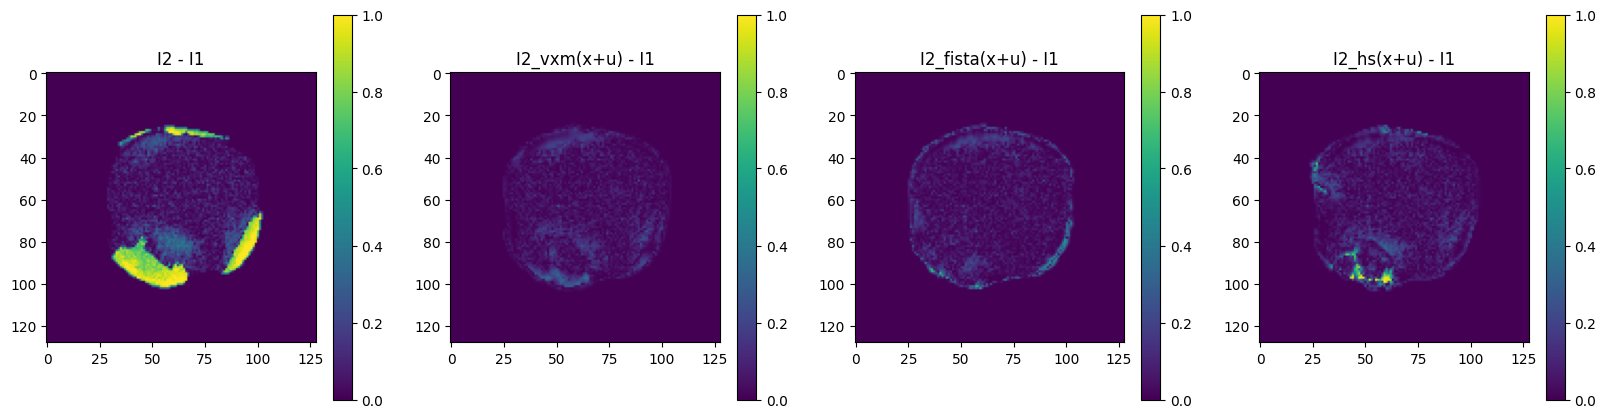

In [37]:
warped_vxm = ws_synth

z_stack = 15

diff0 = np.abs(img_padded_synth[1, z_stack] - img_padded_synth[0, z_stack])
diff1 = np.abs(warped_vxm[z_stack] - img_padded_synth[0, z_stack])
diff2 = np.abs(warped_fista[z_stack] - img_padded_synth[0, z_stack])
diff3 = np.abs(warped_hs[z_stack] - img_padded_synth[0, z_stack])

vmin = min(diff0.min(), diff1.min(), diff2.min(), diff3.min())
vmax = max(diff0.max(), diff1.max(), diff2.max(), diff3.max())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

im0 = axes[0].imshow(diff0, vmin=vmin, vmax=vmax)
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I2 - I1')

im1 = axes[1].imshow(diff1, vmin=vmin, vmax=vmax)
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('I2_vxm(x+u) - I1')

im2 = axes[2].imshow(diff2, vmin=vmin, vmax=vmax)
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('I2_fista(x+u) - I1')

im3 = axes[3].imshow(diff3, vmin=vmin, vmax=vmax)
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('I2_hs(x+u) - I1')

plt.show()

In [38]:
diff_im = img_padded_synth[1] - img_padded_synth[0]
diff_fista = warped_fista - img_padded_synth[0]
diff_hs = warped_hs - img_padded_synth[0]
diff_vxm = warped_vxm - img_padded_synth[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im))
print('warped_fista - I1:', np.linalg.norm(diff_fista))
print('warped_hs - I1:', np.linalg.norm(diff_hs))
print('warped_vxm - I1:', np.linalg.norm(diff_vxm))

print('RMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped_fista - I1:', rmse_(diff_fista))
print('warped_hs - I1:', rmse_(diff_hs))
print('warped_vxm - I1:', rmse_(diff_vxm))


Norms
I2 - I1: 81.198
warped_fista - I1: 22.131086
warped_hs - I1: 22.368484
warped_vxm - I1: 13.18521
RMSE
I2 - I1: 0.112139955
warped_fista - I1: 0.030564535
warped_hs - I1: 0.0308924
warped_vxm - I1: 0.018209673


# Mechanics

In [103]:
strain_fista = strain_mask(dis_fista[:,1:], new_spacing, mask_padded[0])
strain_hs = strain_mask(dis_hs[:,1:], [1, 1, 1], mask_padded[0])
strain_vxm = strain_mask(dis_vxm, [1, 1, 1], mask_padded[0])

In [104]:
def_fista = deformation(strain_fista)
def_hs = deformation(strain_hs)
def_vxm = deformation(strain_vxm)

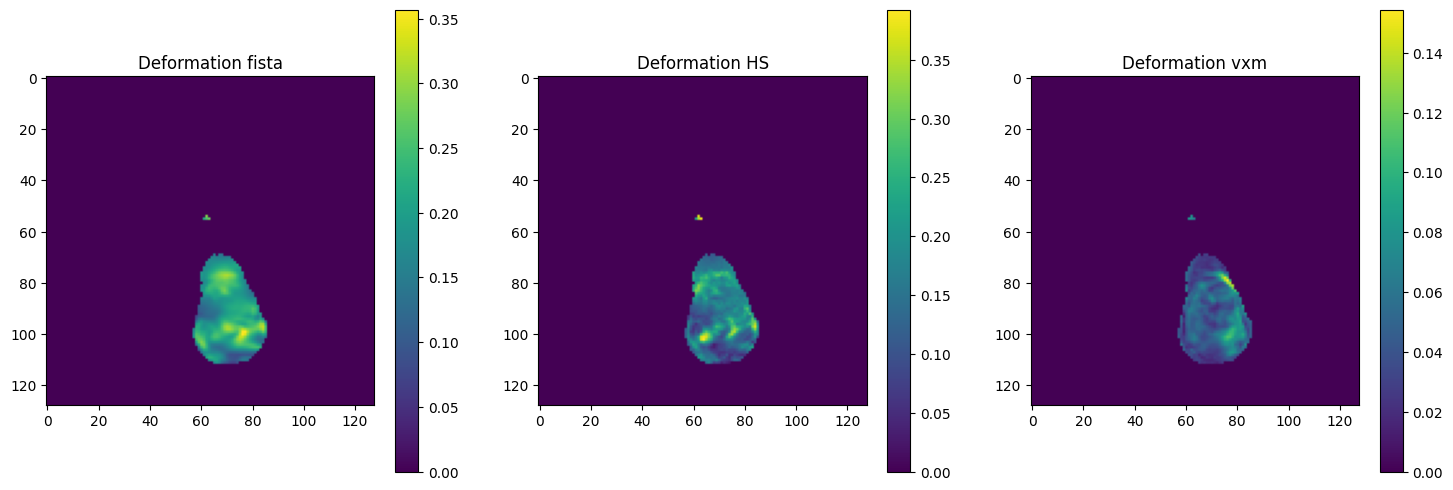

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
im0 = axes[0].imshow(def_fista[0, z_stack])
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('Deformation fista')
im1 = axes[1].imshow(def_hs[0, z_stack])
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('Deformation HS')
im2 = axes[2].imshow(def_vxm[0, z_stack])
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('Deformation vxm')
plt.show()

In [37]:
folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
save_path = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')

with open("configs/optical_flow.yaml", "r") as f:
    cfg = yaml.safe_load(f)

for path_img in folder.iterdir():
    img_padded, spacing = get_img_spacing(path_img, target_d=32, target_h=128, target_w=128, multiple=16, default_spacing=[1.0, 0.13, 0.13])
        
    mask_padded = img_padded[0] > 0.1
    
    fista_params = SimpleNamespace(**cfg["optical_flow"]["fista"])
    hs_params = SimpleNamespace(**cfg["optical_flow"]["hs"])
    tvl1_params = SimpleNamespace(**cfg["optical_flow"]["tvl1"])
    dis_fista = fista_of(img_padded, fista_params, global_flow=True, spacing=spacing)
    dis_hs = hs_of(img_padded, hs_params, True)
    dis_tvl1 = tv_l1(img_padded, tvl1_params, True)

    dis_fista_ = dis_fista[:, 1:, :, :, :]
    dis_fista_final = np.stack(
        [dis_fista_[i] * mask_padded for i in range(dis_fista_.shape[0])]
    )

    dis_hs_ = dis_hs[:, 1:, :, :, :]
    dis_hs_final = np.stack(
        [dis_hs_[i] * mask_padded * spacing[i] for i in range(dis_hs_.shape[0])]
    )

    dis_tvl1_ = dis_tvl1[:, 1:, :, :, :]
    dis_tvl1_final = np.stack(
        [dis_tvl1_[i] * mask_padded * spacing[i] for i in range(dis_tvl1_.shape[0])]
    )
    save_path.mkdir(exist_ok=True)
    np.save(save_path / f"flow_fista_{path_img.name}", dis_fista_final)
    np.save(save_path / f"flow_hs_{path_img.name}", dis_hs_final)
    np.save(save_path / f"flow_tvl1_{path_img.name}", dis_tvl1_final)

KeyboardInterrupt: 

In [ ]:
from optical_flow.algorithms import warp

def compute_mse_images(computed_flows_dir, images_dir, model, z_stack):
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm', '').replace('.npy', '')
        img_path = os.path.join(images_dir, base_name)
        
        img_padded, displacement, warped_source = get_img_and_results(img_path, model, default_spacing=[1.0, 0.13, 0.13])

        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}.npy")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}.npy")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}.npy")
        
        warped_fista = warp(img_padded[1], dis_fista[:, 0])
        warped_hs = warp(img_padded[1], dis_hs[:, 0])       
        warped_tvl1 = warp(img_padded[1], dis_tvl1[:, 0])
        warped_vxm = warped_source.detach().numpy()[0,0]

        fig, axes = plt.subplots(1, 5, figsize=(25, 5))
        im0 = axes[0].imshow(img_padded[0, z_stack] -  img_padded[1, z_stack])
        fig.colorbar(im0, ax = axes[0])
        axes[0].set_title('Target - source')
        im1 = axes[1].imshow(img_padded[0, z_stack] -  warped_fista[z_stack])
        fig.colorbar(im1, ax = axes[1])
        axes[1].set_title('Fista warped - source')
        im2 = axes[2].imshow(img_padded[0, z_stack] -  warped_hs[z_stack])
        fig.colorbar(im2, ax = axes[2])
        axes[2].set_title('HS warped - source')
        im3 = axes[3].imshow(img_padded[0, z_stack] -  warped_tvl1[z_stack])
        fig.colorbar(im3, ax = axes[3])
        axes[3].set_title('TVL1 warped - source')
        im4 = axes[4].imshow(img_padded[0, z_stack] -  warped_vxm[z_stack])
        fig.colorbar(im4, ax = axes[4])
        axes[4].set_title('VXM warped - source')
        plt.show()

In [31]:
compute_mse_images(save_path, folder, model_aniso, 15)

TypeError: get_img_and_results() got an unexpected keyword argument 'spacing'

In [25]:
folder = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/testOF')

save_path = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/computed_flows')
save_path.mkdir(exist_ok=True)

save_flow_vxm(folder, model_aniso, save_path, '')

ValueError: too many values to unpack (expected 3)

In [68]:
def compute_rmse_all_methods(computed_flows_dir, gt_flow_dir):
    rmse_summary = []
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm_*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm_', '')

        ugt_name = base_name.replace('_img.npy', '_ugt.npy')

        ugt_path = gt_flow_dir / ugt_name
        dis_gt_init = np.load(ugt_path)
        dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}")
        dis_vxm = np.load(computed_flows_dir / f"flow_vxm_{base_name}")
        
        rmse_fista = rmse(dis_fista[:,0], dis_gt)
        rmse_hs = rmse(dis_hs[:,0], dis_gt)
        rmse_tvl1 = rmse(dis_tvl1[:,0], dis_gt)
        rmse_vxm = rmse(dis_vxm[:,0], dis_gt)

        rmse_summary.append({
            "img_name": cf_name,
            "rmse_fista": float(rmse_fista),
            "rmse_hs": float(rmse_hs),
            "rmse_tvl1": float(rmse_tvl1),
            "rmse_vxm": float(rmse_vxm),
        })
    
    return rmse_summary

def compute_lame(E, nu):
    """
    Computes the Lamé parameters (μ and λ) from Young’s modulus and Poisson’s ratio.

    Args:
        E (float):
            Young’s modulus of the material.
        nu (float):
            Poisson’s ratio of the material.

    Returns:
        tuple[float, float]:
            - `mu_e` (float): Shear modulus (μ).
            - `lambda_e` (float): First Lamé parameter (λ).
    """
    lambda_e = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    mu_e = E / (2.0 * (1.0 + nu))
    return mu_e, lambda_e


def compute_mec_stuff(name, computed_flows_dir, gt_flow_dir, mask, normals):

    ugt_name = name.replace('_img.npy', '_ugt.npy')

    ugt_path = gt_flow_dir / ugt_name
    
    matchE = re.search(r"E_(\d+)", name)
    if matchE is not None:
        E = float(matchE.group(1))
        
    matchnu = re.search(r"_nu_(\d+)", name)
    if matchnu is not None:
        nu = float(matchnu.group(1))
    
    mu, lambda_ = compute_lame(E, nu)
    
    displacements = {
        "gt":    np.load(ugt_path),
        "fista": np.load(computed_flows_dir / f"flow_fista_{name}"),
        "hs":    np.load(computed_flows_dir / f"flow_hs_{name}"),
        "tvl1":  np.load(computed_flows_dir / f"flow_tvl1_{name}"),
        "vxm":   np.load(computed_flows_dir / f"flow_vxm_{name}")
    }
    
    results = {}
    dis_gt_init = displacements["gt"]
    dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
    dis_gt = np.expand_dims(dis_gt, axis=1)
    strain_gt = strain_mask(dis_gt, [1, 1, 1], mask)
    def_grad_gt = deformation(strain_gt)
    stress_gt = stress_mask(strain_gt, mu, lambda_)
    traction_gt = compute_traction_3d(stress_gt[:,:,0], -normals)

    results["gt"] = {
        "displacement": dis_gt,        
        "deformation":  def_grad_gt,
        "strain":       strain_gt,
        "stress":       stress_gt,
        "normals":      normals,
        "traction":     traction_gt,
    }

    methods = ["fista", "hs", "tvl1", "vxm"]
    
    for method in methods:
        dis = displacements[method]
        
        strain = strain_mask(dis, [1, 1, 1], mask)
        def_grad = deformation(strain)
        stress = stress_mask(strain, mu, lambda_)
        traction = compute_traction_3d(stress[:,:,0], -normals)

        results[method] = {
            "displacement": dis,        
            "deformation":  def_grad,
            "strain":       strain,
            "stress":       stress,
            "normals":      normals,
            "traction":     traction,
            
            "rmse_displacement": rmse(dis, dis_gt),
            "rmse_deformation":  rmse(def_grad, def_grad_gt),
            "rmse_strain":       rmse(strain, strain_gt),
            "rmse_stress":       rmse(stress, stress_gt),
            "rmse_traction":     rmse(traction, traction_gt),
        }

    return results

In [ ]:
computed_flows_dir = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/computed_flows')
gt_flow_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')

rmse_summary = compute_rmse_all_methods(computed_flows_dir, gt_flow_dir)

methods = ['rmse_fista', 'rmse_hs', 'rmse_tvl1', 'rmse_vxm']

avg = {m: np.mean([d[m] for d in rmse_summary]) for m in methods}

for method, value in avg.items():
    print(f"{method} : {value}")

In [ ]:
img_name = 'E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy' #'E_1000.0_nu_0.4_nb_zones_9_im_01_seed_01_img.npy'
folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
img_raw = np.load(folder / f"{img_name}")
q1, q99 = np.quantile(img_raw, [0.01, 0.99])
img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

mask = img_padded[0] > 0.1

mask_eroded = ndi.binary_erosion(mask)
inner_boundary_gt = mask_eroded & (~ndi.binary_erosion(mask_eroded))
normals = compute_normals_from_mask_3d(mask_eroded)
normals[:, ~inner_boundary_gt] = 0

results = compute_mec_stuff(img_name, computed_flows_dir, gt_flow_dir, normals) 

In [42]:
metrics = ["displacement", "deformation", "strain", "stress", "traction"]
methods = ["fista", "hs", "tvl1", 'vxm']

for metric in metrics:
    print(f"\n{metric}")
    for method in methods:
        val = results[method][f"rmse_{metric}"]
        print(f"{method:<8} : {val:.6e}")


displacement
fista    : 1.428353e-01
hs       : 1.563871e-01
tvl1     : 1.521091e-01
vxm      : 1.635397e-01

deformation
fista    : 5.114334e-02
hs       : 4.766799e-02
tvl1     : 4.865333e-02
vxm      : 4.872380e-02

strain
fista    : 2.076933e-02
hs       : 2.262412e-02
tvl1     : 2.357346e-02
vxm      : 2.443072e-02

stress
fista    : 2.076933e+01
hs       : 2.262412e+01
tvl1     : 2.357346e+01
vxm      : 2.443072e+01

traction
fista    : 2.124405e+01
hs       : 2.268356e+01
tvl1     : 2.322456e+01
vxm      : 2.411972e+01


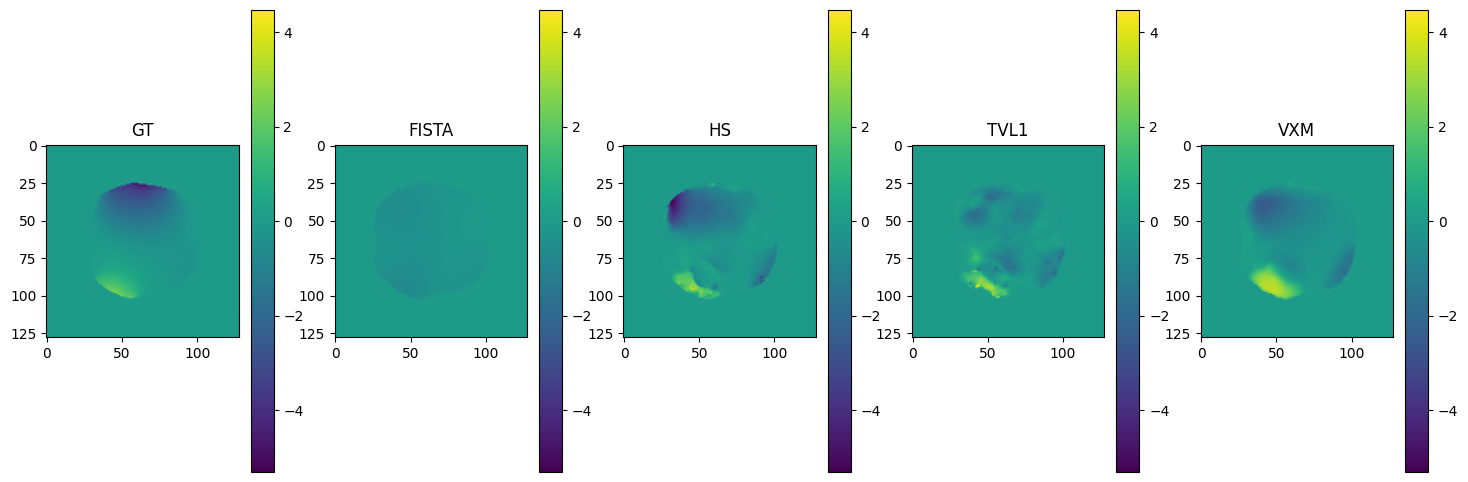

In [50]:
methods = ["gt", "fista", "hs", "tvl1", "vxm"]
method_titles = ["GT", "FISTA", "HS", "TVL1", "VXM"]
frame = 15
ax = 0

fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['displacement'][ax, 0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['displacement'][ax, 0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

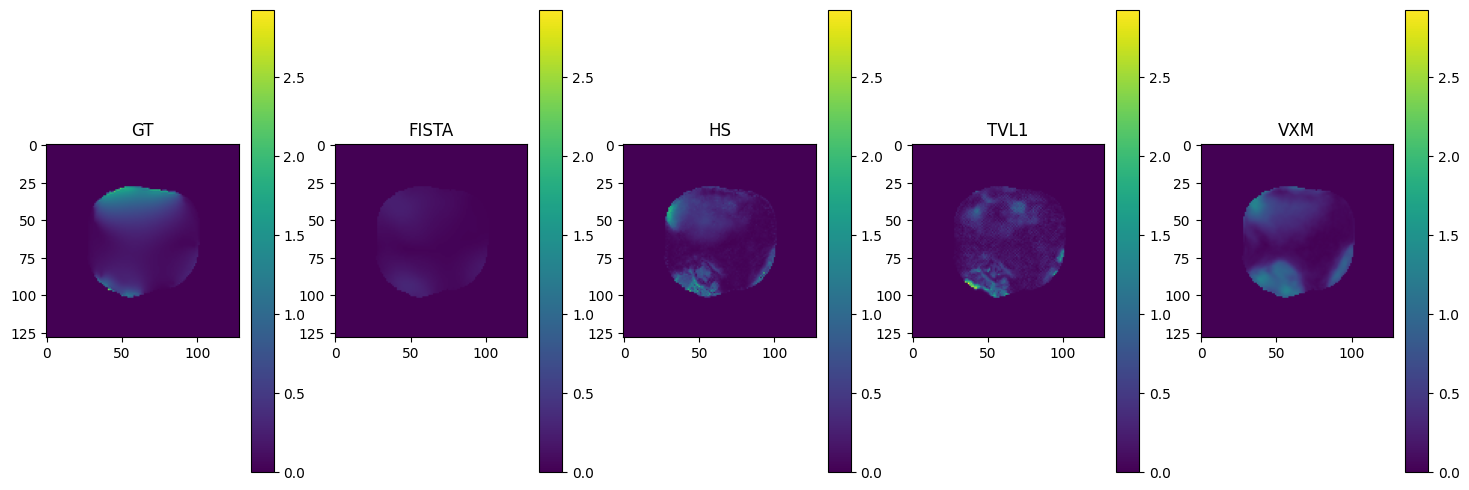

In [51]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['deformation'][0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['deformation'][0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

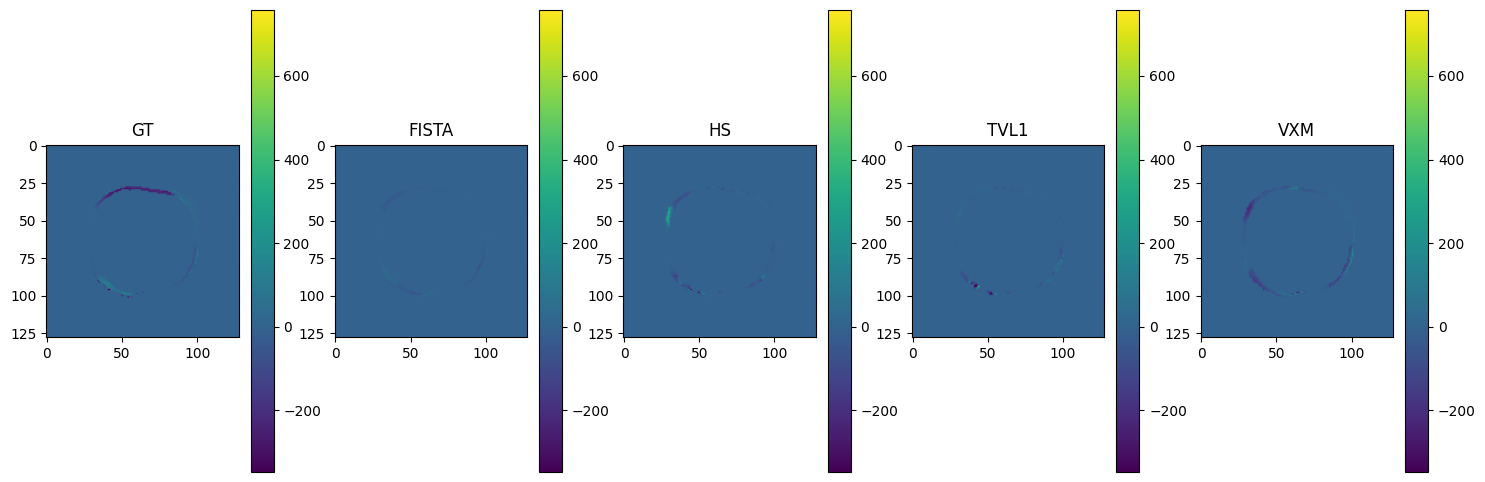

In [52]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['traction'][1, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['traction'][2, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)